3.12.2 (tags/v3.12.2:6abddd9, Feb  6 2024, 21:26:36) [MSC v.1937 64 bit (AMD64)] 2.4.4 3.0.2
f1: sin(x)+x OLS θ = [0.03224099 1.6419487 ] | Ridge θ = [0.0323457  1.64059163]
f2: x^2 OLS θ = [1.38776818 0.15328403] | Ridge θ = [1.38779954 0.15314461]
f3: |x| OLS θ = [0.93495258 0.02372729] | Ridge θ = [0.9349552  0.02370291]
f4: 1{x>=0} OLS θ = [0.51821282 0.40118018] | Ridge θ = [0.51823733 0.40073156]


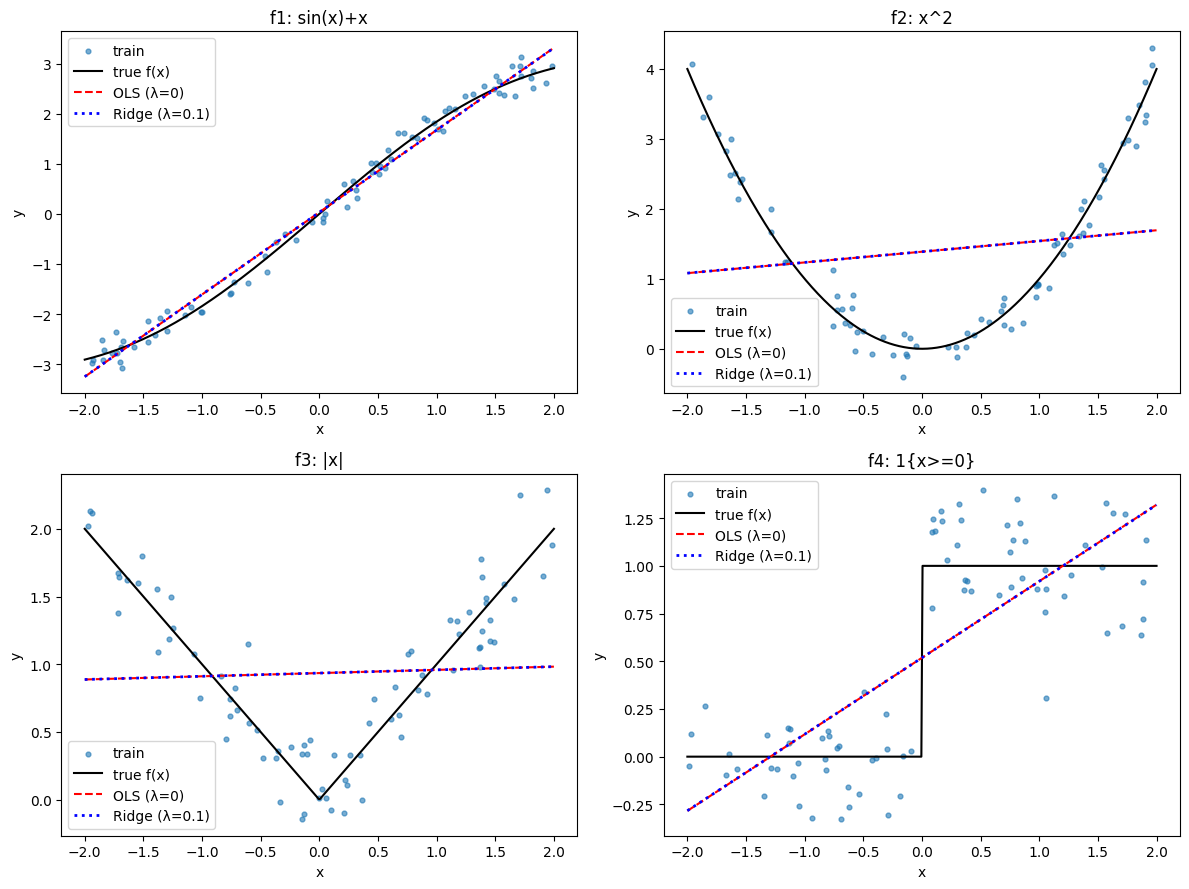


=== f1: sin(x)+x ===
  d    lam    train      val
 1  0.000 0.062249 0.076039
 1  0.001 0.062249 0.076045
 1  0.010 0.062249 0.076093
 1  0.100 0.062293 0.076613
 1  1.000 0.066428 0.084673
 1 10.000 0.314061 0.322014
 2  0.000 0.062249 0.076047
 2  0.001 0.062249 0.076052
 2  0.010 0.062249 0.076104
 2  0.100 0.062293 0.076651
 2  1.000 0.066449 0.084853
 2 10.000 0.314008 0.319659
 5  0.000 0.031701 0.049215
 5  0.001 0.031703 0.049117
 5  0.010 0.031780 0.048469
 5  0.100 0.033350 0.047800
 5  1.000 0.059768 0.079495
 5 10.000 0.313975 0.390950
10  0.000 0.031554 0.050353
10  0.001 0.031588 0.049604
10  0.010 0.031767 0.048808
10  0.100 0.033396 0.048339
10  1.000 0.056831 0.077883
10 10.000 0.329564 0.420113

=== f2: x^2 ===
  d    lam    train      val
 1  0.000 1.552549 1.368540
 1  0.001 1.552549 1.368534
 1  0.010 1.552549 1.368489
 1  0.100 1.552550 1.368036
 1  1.000 1.552589 1.363702
 1 10.000 1.554848 1.334005
 2  0.000 0.042983 0.050547
 2  0.001 0.042983 0.050551
 2  0.0

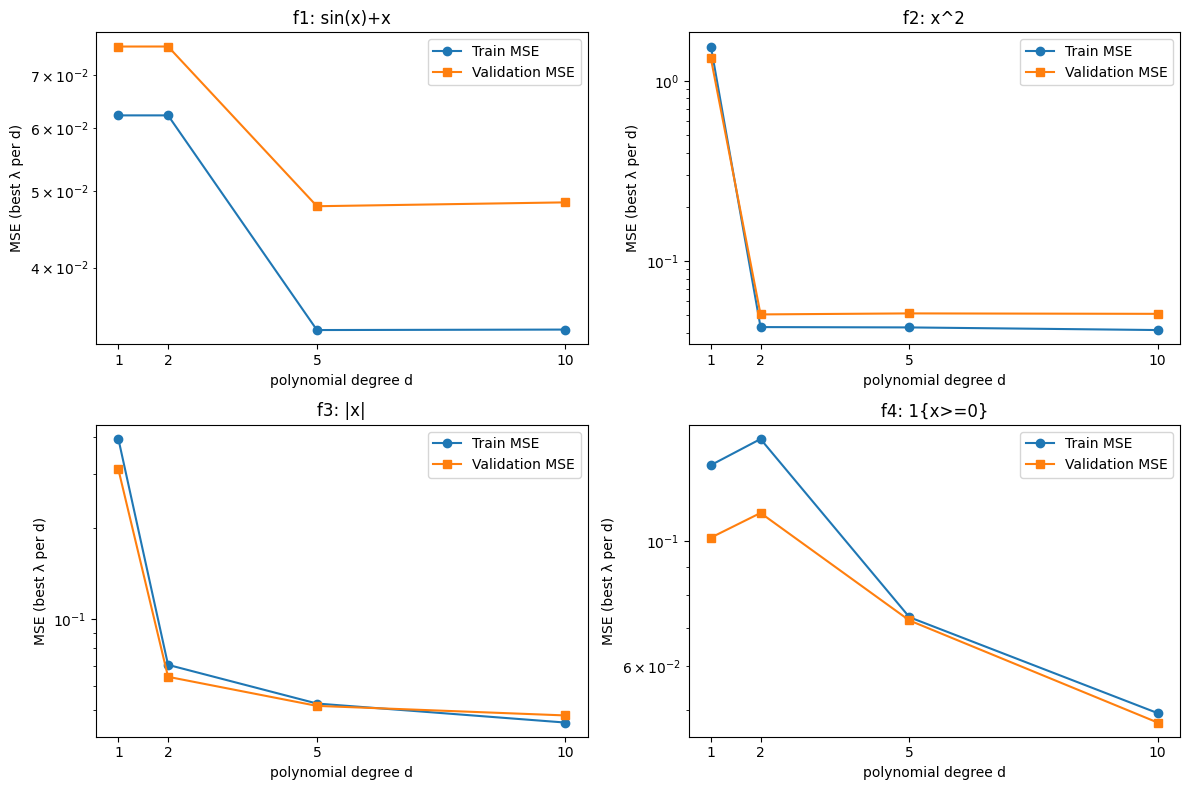

In [ ]:
import sys, numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print(sys.version, np.__version__, pd.__version__)

SEED, SIGMA = 42, 0.2
funcs = {
    "f1: sin(x)+x": lambda x: np.sin(x) + x,
    "f2: x^2":      lambda x: x**2,
    "f3: |x|":      np.abs,
    "f4: 1{x>=0}":  lambda x: (x >= 0).astype(float),
}

children = np.random.SeedSequence(SEED).spawn(len(funcs))
data = {}
for (name, f), ss in zip(funcs.items(), children):
    rng = np.random.default_rng(ss)
    def make(n):
        x = rng.uniform(-2, 2, n)
        return x, f(x) + rng.normal(0, SIGMA, n)
    data[name] = dict(train=make(80), val=make(40), test=make(200))

def design(x, d=1, s=1.0):
    z = x / s
    return np.column_stack([z**k for k in range(d + 1)])

def fit_ols(X, y):
    return np.linalg.lstsq(X, y, rcond=None)[0]

def fit_ridge(X, y, lam):
    D = np.eye(X.shape[1]); D[0, 0] = 0
    return np.linalg.solve(X.T @ X + lam * D, X.T @ y)

def fit(X, y, lam):
    return fit_ols(X, y) if lam == 0 else fit_ridge(X, y, lam)

mse = lambda y, yh: np.mean((y - yh) ** 2)

grid = np.linspace(-2, 2, 400)
fig, axs = plt.subplots(2, 2, figsize=(12, 9))
for ax, (name, f) in zip(axs.ravel(), funcs.items()):
    x, y = data[name]["train"]
    X = design(x, 1)
    th_ols, th_rdg = fit_ols(X, y), fit_ridge(X, y, 0.1)
    G = design(grid, 1)
    ax.scatter(x, y, s=12, alpha=.6, label="train")
    ax.plot(grid, f(grid), 'k', label="true f(x)")
    ax.plot(grid, G @ th_ols, 'r--', label="OLS (λ=0)")
    ax.plot(grid, G @ th_rdg, 'b:', lw=2, label="Ridge (λ=0.1)")
    ax.set(title=name, xlabel="x", ylabel="y"); ax.legend()
    print(name, "OLS θ =", th_ols, "| Ridge θ =", th_rdg)
plt.tight_layout(); plt.show()

degrees = [1, 2, 5, 10]
lams = [0, 0.001, 0.01, 0.1, 1, 10]
summary, curves = [], {}

for name in funcs:
    (xtr, ytr), (xva, yva), (xte, yte) = (data[name][k] for k in ("train", "val", "test"))
    rows = []
    for d in degrees:
        Xtr, Xva = design(xtr, d, 2), design(xva, d, 2)
        for lam in lams:
            th = fit(Xtr, ytr, lam)
            rows.append(dict(d=d, lam=lam, train=mse(ytr, Xtr @ th), val=mse(yva, Xva @ th)))
    df = pd.DataFrame(rows)
    print(f"\n=== {name} ===\n", df.to_string(index=False))

    best = df.loc[df["val"].idxmin()]                     
    d, lam = int(best.d), best.lam
    th = fit(design(xtr, d, 2), ytr, lam)
    test_mse = mse(yte, design(xte, d, 2) @ th)            
    summary.append(dict(function=name, d=d, lam=lam, train=best.train, val=best.val, test=test_mse))
    curves[name] = df.loc[df.groupby("d")["val"].idxmin()].sort_values("d")

print("\n", pd.DataFrame(summary).to_string(index=False))

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, c) in zip(axs.ravel(), curves.items()):
    ax.plot(c.d, c.train, 'o-', label="Train MSE")
    ax.plot(c.d, c.val, 's-', label="Validation MSE")
    ax.set(title=name, xlabel="polynomial degree d", ylabel="MSE (best λ per d)", yscale="log", xticks=degrees) 
    ax.legend()
plt.tight_layout(); plt.show()